# Calibration 1 — Chọn siêu tham số: dạng GARCH, số nhân tố, số quan sát đuôi $k$

Các giai đoạn trước cố định ba lựa chọn: GARCH(1,1)-t, một nhân tố thị trường, $k = \lfloor n^{0,4}\rfloor$. Notebook này chọn lại chúng **từ dữ liệu**:

| Siêu tham số | Cách chọn | Nguồn |
|---|---|---|
| Dạng GARCH | BIC của 4 dạng (GARCH-t, GJR-GARCH-t, EGARCH-t, GARCH-skew t) cho từng mã | Bollerslev 1986; Glosten–Jagannathan–Runkle 1993; Nelson 1991 |
| Số nhân tố $K$ | Tỷ số giá trị riêng ER và tỷ số tăng trưởng GR | Ahn & Horenstein (2013), *Econometrica* 81(3), doi:10.3982/ECTA8968 |
| Số mũ $\nu$ của $k = \lfloor n^\nu\rfloor$ | (a) vùng ổn định của thứ tự EASE theo $\nu$; (b) mô phỏng hiệu chỉnh: SID nhỏ nhất trên dữ liệu sinh từ mô hình khớp với dữ liệu thật | Gnecco và cs. (2021), mục 5.1 |

## 0. Thiết lập

In [1]:
import sys, warnings
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "sql").is_dir() and (p / "src").is_dir())
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import eda_utils as U
import causal_tail as CT
import causal_baselines as CB
import tail_preprocessing as TP

U.apply_publication_style()
pd.set_option("display.float_format", "{:,.3f}".format)
SYMBOLS, COL, PAL = U.SYMBOLS, U.SYMBOL_COLORS, U.PALETTE
FOLDER = "calibration"                      # hình → report/figure/processing, bảng → report/table/processing
METHOD_COLORS = {"EASE": PAL["blue_main"], "Pairwise LiNGAM": PAL["red_strong"], "ICA-LiNGAM": PAL["green_3"],
                 "Rank PC": PAL["violet"], "Ngẫu nhiên": PAL["neutral"]}

import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)
import validation as V
import calibration as C
from scipy import stats
from joblib import Parallel, delayed
P = len(SYMBOLS)
OFF = ~np.eye(P, dtype=bool)
Z = pd.read_parquet(ROOT / "data" / "processed" / "garch_std_resid_market.parquet")
z = Z[SYMBOLS]
n, K = len(z), CT.default_k(len(z))
NU_CAL = 0.35                     # ν chọn ở Calibration 01 (mô phỏng hiệu chỉnh + độ ổn định)
KC = CT.default_k(n, NU_CAL)
print(f"n = {n} phiên, {P} mã, k(ν=0,4) = {K}, k hiệu chỉnh (ν={NU_CAL}) = {KC}")

n = 2118 phiên, 20 mã, k(ν=0,4) = 21, k hiệu chỉnh (ν=0.35) = 14


## 1. Dạng GARCH

**Tính gì:** với mỗi mã, khớp 4 dạng trên lợi suất log ($\times 100$) và so BIC $= -2\log L + m\ln T$ ($m$: số tham số). Chênh lệch $\Delta\text{BIC} > 10$
so với dạng tốt nhất được coi là bằng chứng mạnh (Kass & Raftery, 1995).

- **GJR-GARCH:** $\sigma_t^2 = \omega + (a + \gamma\,\mathbb 1\{\varepsilon_{t-1}<0\})\varepsilon_{t-1}^2 + b\sigma_{t-1}^2$ — tin xấu tăng biến động mạnh hơn (hiệu ứng đòn bẩy).
- **EGARCH:** mô hình $\ln\sigma_t^2$, cũng có hệ số bất đối xứng. **skew t:** nhiễu Student-t lệch (Hansen, 1994).

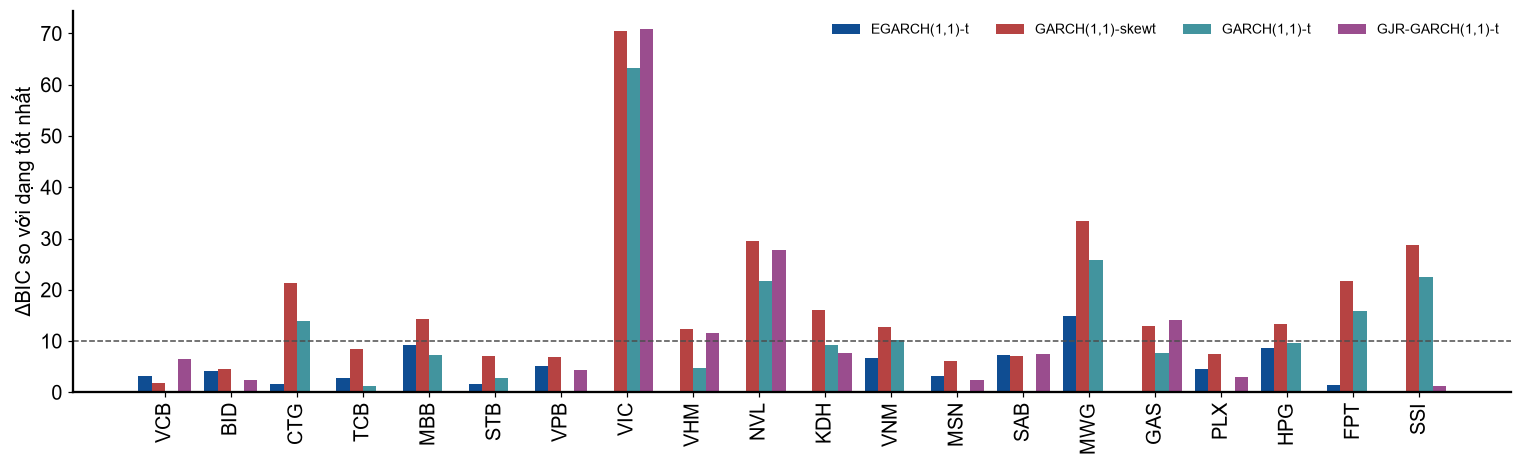

Số mã mà mỗi dạng là tốt nhất: {'GJR-GARCH(1,1)-t': 8, 'GARCH(1,1)-t': 6, 'EGARCH(1,1)-t': 6}
Tất cả hội tụ: True


dang,"EGARCH(1,1)-t","GARCH(1,1)-skewt","GARCH(1,1)-t","GJR-GARCH(1,1)-t"
ma,,,,
VCB,3.300,1.900,0.000,6.500
BID,4.200,4.600,0.000,2.400
CTG,1.600,21.300,13.800,0.000
TCB,2.700,8.400,1.200,0.000
MBB,9.200,14.300,7.400,0.000
STB,1.600,7.000,2.800,0.000
VPB,5.000,6.900,0.000,4.400
VIC,0.000,70.400,63.200,70.900
VHM,0.000,12.400,4.800,11.500


In [2]:
con = U.connect()
r = con.execute("SELECT * FROM v_returns_wide").df().set_index("time")[SYMBOLS].dropna()
gt = C.garch_spec_table(r)
gt["dBIC"] = gt.bic - gt.groupby("ma").bic.transform("min")
best = gt.loc[gt.groupby("ma").bic.idxmin()].set_index("ma").loc[SYMBOLS]
piv = gt.pivot(index="ma", columns="dang", values="dBIC").loc[SYMBOLS]
U.save_table(piv, "01_garch_dbic", FOLDER)

fig, ax = plt.subplots(figsize=(14, 4.4))
x = np.arange(P); w = 0.2
cols = [PAL["blue_main"], PAL["red_strong"], PAL["teal"], PAL["violet"]]
for i, (sp, c) in enumerate(zip(piv.columns, cols)):
    ax.bar(x + (i - 1.5) * w, piv[sp], w, color=c, label=sp)
ax.axhline(10, color=PAL["gray_dark"], ls="--", lw=1)
ax.set_xticks(x, SYMBOLS, rotation=90); ax.set_ylabel("ΔBIC so với dạng tốt nhất")
ax.legend(fontsize=9, ncol=4, loc="upper right")
U.finalize_figure(fig, "01_garch_dbic", folder=FOLDER); plt.show()
print("Số mã mà mỗi dạng là tốt nhất:", best.dang.value_counts().to_dict())
print("Tất cả hội tụ:", bool(gt.converged.all()))
piv.round(1)

In [3]:
# Ảnh hưởng của lựa chọn GARCH lên kết quả: thứ tự EASE với phần dư của dạng tốt nhất theo BIC (từng mã) so với GARCH-t
from arch import arch_model
zbest = {}
for s in SYMBOLS:
    spec = C.GARCH_SPECS[best.loc[s, "dang"]]
    fit = arch_model(r[s] * 100, mean="Constant", **spec).fit(disp="off")
    zbest[s] = fit.std_resid
zbest = pd.DataFrame(zbest).dropna().loc[z.index.intersection(pd.DataFrame(zbest).dropna().index)]
o_t, o_best = CT.ease(CT.tail_coef_matrix(z.loc[zbest.index], k=K)), CT.ease(CT.tail_coef_matrix(zbest, k=K))
print(f"Đồng thuận thứ tự EASE (GARCH-t vs dạng tốt nhất): {TP.order_agreement(o_t, o_best):.3f}")
print(f"Tương quan Ψ̂ giữa hai cách lọc: {np.corrcoef(CT.tail_coef_matrix(z.loc[zbest.index], k=K).values[OFF], CT.tail_coef_matrix(zbest, k=K).values[OFF])[0, 1]:.3f}")

Đồng thuận thứ tự EASE (GARCH-t vs dạng tốt nhất): 0.968
Tương quan Ψ̂ giữa hai cách lọc: 0.954


### Phân tích


- Không có dạng nào thắng áp đảo: **GJR-GARCH-t tốt nhất ở 8 mã** (chủ yếu ngân hàng: CTG, TCB, MBB, STB; cùng VNM, MWG, HPG, FPT), GARCH-t ở 6 mã, EGARCH-t ở 6 mã
  (bất động sản VIC, VHM, NVL, KDH; GAS; SSI). Skew-t không thắng ở mã nào. Mọi khớp đều hội tụ.
- Chênh lệch rất lớn ở bất động sản: với VIC, GARCH-t kém EGARCH 63 đơn vị BIC; NVL 22; MWG (GARCH-t kém GJR 26) — hiệu ứng đòn bẩy (tin xấu tăng biến động mạnh hơn) rõ ở các mã này.
- **Nhưng lựa chọn dạng GARCH hầu như không đổi kết quả đuôi:** dùng dạng tốt nhất theo BIC cho từng mã, thứ tự EASE đồng thuận **0,968** với GARCH-t và tương quan
  $\hat\Psi$ giữa hai cách lọc **0,954**. Giữ GARCH(1,1)-t làm cấu hình chung để đơn giản, ghi nhận độ vững này.

## 2. Số nhân tố chung $K$

**Công thức (Ahn & Horenstein, 2013).** Với $\mu_1 \ge \mu_2 \ge \dots$ là giá trị riêng của ma trận hiệp phương sai mẫu của $z$ đã chuẩn hoá,
$V_k = \sum_{j>k}\mu_j$ và $\mu_0 = V_0/\ln\min(N,T)$:
$$\mathrm{ER}(k) = \frac{\mu_k}{\mu_{k+1}},\qquad \mathrm{GR}(k) = \frac{\ln(1 + \mu_k/V_k)}{\ln(1 + \mu_{k+1}/V_{k+1})},\qquad \hat K = \arg\max_{0\le k\le k_{\max}}.$$
Ý tưởng: nhân tố chung tạo một "bậc" lớn trong dãy giá trị riêng; số nhân tố là vị trí của bậc lớn nhất.

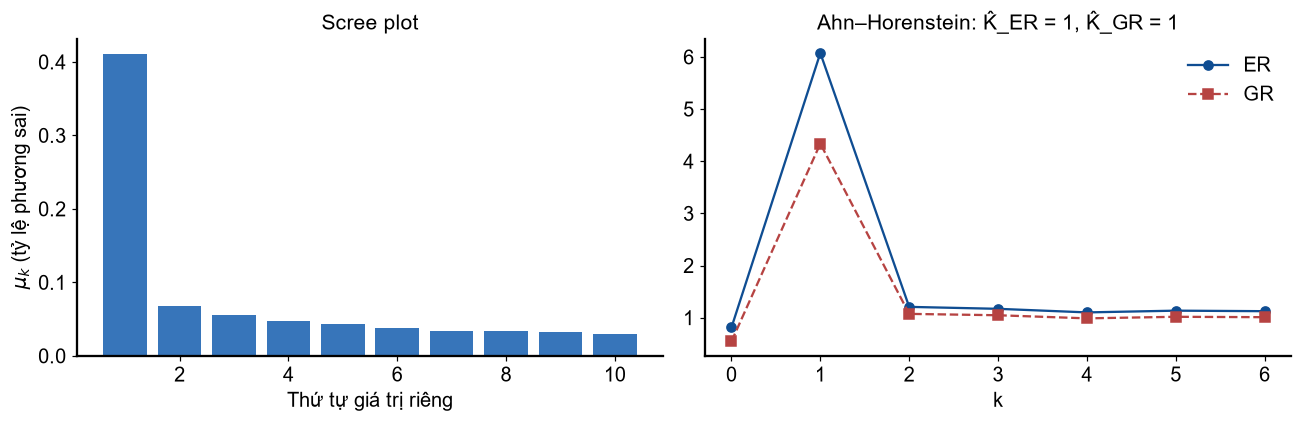

μ1 = 0.411 (41% phương sai), μ2 = 0.068


,ER,GR
k,,
0,0.810,0.540
1,6.070,4.340
2,1.210,1.070
3,1.170,1.050
4,1.100,0.990
5,1.130,1.020
6,1.120,1.010


In [4]:
ah = C.n_factors_ahn_horenstein(z, kmax=6)
tab = pd.DataFrame({"ER": ah["ER"], "GR": ah["GR"]}, index=pd.Index(range(7), name="k"))
U.save_table(tab, "01_ahn_horenstein", FOLDER)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(range(1, 11), ah["eigen"][:10], color=PAL["blue_secondary"])
axes[0].set_xlabel("Thứ tự giá trị riêng"); axes[0].set_ylabel(r"$\mu_k$ (tỷ lệ phương sai)"); axes[0].set_title("Scree plot")
axes[1].plot(tab.index, tab.ER, "o-", color=PAL["blue_main"], label="ER")
axes[1].plot(tab.index, tab.GR, "s--", color=PAL["red_strong"], label="GR")
axes[1].set_xlabel("k"); axes[1].set_title(f"Ahn–Horenstein: K̂_ER = {ah['K_ER']}, K̂_GR = {ah['K_GR']}"); axes[1].legend()
U.finalize_figure(fig, "01_number_of_factors", folder=FOLDER); plt.show()
print(f"μ1 = {ah['eigen'][0]:.3f} ({ah['eigen'][0]:.0%} phương sai), μ2 = {ah['eigen'][1]:.3f}")
tab.round(2)

### Phân tích


- **$\hat K = 1$ theo cả ER (6,07) và GR (4,34)** — bậc lớn duy nhất nằm giữa giá trị riêng thứ nhất (0,41 tức 41% phương sai) và thứ hai (0,07).
- Các giá trị riêng tiếp theo (0,068; 0,056; 0,048…) giảm đều, không có bậc thứ hai: nhân tố ngành tồn tại (EDA: PC2 Vingroup, PC3 năng lượng–tiêu dùng) nhưng **yếu so với
  nhân tố thị trường**, nên tiêu chí Ahn–Horenstein chỉ giữ một nhân tố. Calibration 02 vì vậy dùng $K = 1$ cho PCA và thử thêm nhân tố ngành bằng LOO.

## 3. Chọn $k$: vùng ổn định của thứ tự EASE

**Tính gì:** thứ tự EASE với $\nu \in \{0{,}20; 0{,}25; \dots; 0{,}70\}$ trên dữ liệu thô $z$ và trên dữ liệu đã khử thị trường (hệ số có điều kiện,
notebook 02); độ đồng thuận cặp với hai $\nu$ kề bên. Chọn $\nu$ ở **vùng phẳng**: thứ tự ít đổi khi $k$ thay đổi nhẹ.

**Ràng buộc biên độ ±7%:** với lợi suất thô, nếu $k$ nhỏ hơn số phiên chạm trần/sàn thì tập cực trị toàn phiên trùng giá trị. Trên $z$ ràng buộc này
yếu hơn (ngưỡng ±7%/σₜ thay đổi theo ngày), nên chỉ ghi số phiên chạm biên để tham khảo.

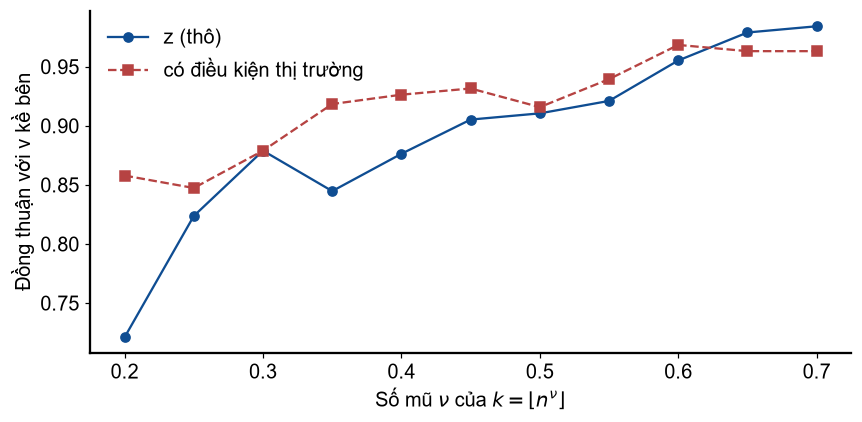

Số phiên chạm trần/sàn mỗi mã: 13.0–96.0 (trung vị 46); k(ν=0,4) = 21, k(ν=0,5) = 46


,k,dong_thuan_lan_can_tho,dong_thuan_lan_can_dieu_kien
nu,,,
0.200,4,0.721,0.858
0.250,6,0.824,0.847
0.300,9,0.879,0.879
0.350,14,0.845,0.918
0.400,21,0.876,0.926
0.450,31,0.905,0.932
0.500,46,0.911,0.916
0.550,67,0.921,0.939
0.600,98,0.955,0.968


In [5]:
nus = np.round(np.arange(0.20, 0.701, 0.05), 2)
ks_raw = C.k_stability(z, nus)
adj_orders = []
for nu in nus:
    adj_orders.append(CT.ease(C.adjusted_tail_coef_matrix(z, k=CT.default_k(n, nu))["adj"]))
agree_adj = [np.mean([TP.order_agreement(o, adj_orders[j]) for j in (i - 1, i + 1) if 0 <= j < len(nus)])
             for i, o in enumerate(adj_orders)]
kst = pd.DataFrame({"k": ks_raw.k, "dong_thuan_lan_can_tho": ks_raw.agree_neighbors, "dong_thuan_lan_can_dieu_kien": agree_adj},
                   index=ks_raw.index)
U.save_table(kst, "01_k_stability", FOLDER)
hits = con.execute("SELECT symbol, SUM((hit_ceiling OR hit_floor)::INT) AS n FROM v_analysis GROUP BY symbol").df().set_index("symbol").n
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(nus, kst.dong_thuan_lan_can_tho, "o-", color=PAL["blue_main"], label="z (thô)")
ax.plot(nus, kst.dong_thuan_lan_can_dieu_kien, "s--", color=PAL["red_strong"], label="có điều kiện thị trường")
ax.set_xlabel(r"Số mũ $\nu$ của $k=\lfloor n^{\nu}\rfloor$"); ax.set_ylabel("Đồng thuận với ν kề bên"); ax.legend()
U.finalize_figure(fig, "01_k_stability", folder=FOLDER); plt.show()
print(f"Số phiên chạm trần/sàn mỗi mã: {hits.min()}–{hits.max()} (trung vị {hits.median():.0f}); k(ν=0,4) = {K}, k(ν=0,5) = {CT.default_k(n, 0.5)}")
kst.round(3)

## 4. Chọn $k$: mô phỏng hiệu chỉnh

**Các bước:** sinh dữ liệu từ mô hình **một nhân tố** (tải $\hat\lambda$ ước lượng từ $z$, nhiễu $t_\nu$ với $\nu$ = bậc tự do GARCH trung bình) cộng một **DAG thưa** giữa
20 mã (mỗi cặp có cạnh với xác suất 0,08, hệ số $U(0{,}2;\,0{,}5)$); chạy EASE trên hệ số có điều kiện thị trường với từng $\nu$; đo SID so với DAG tổ tiên thật.
40 lần lặp, chạy song song. $\nu^\*$ = SID trung bình nhỏ nhất.

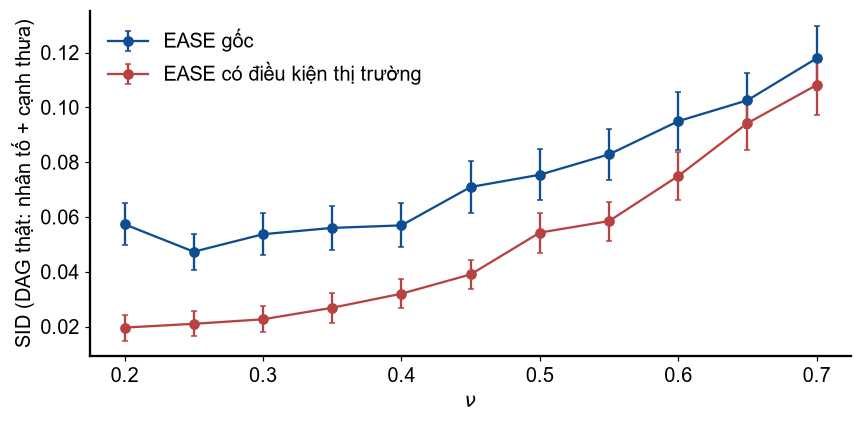

ν tốt nhất: {'dieu_kien': 0.2, 'tho': 0.25}


phuong_phap,dieu_kien,tho
nu,,
0.200,0.020,0.057
0.250,0.021,0.047
0.300,0.023,0.054
0.350,0.027,0.056
0.400,0.032,0.057
0.450,0.039,0.071
0.500,0.054,0.075
0.550,0.058,0.083
0.600,0.075,0.095


In [6]:
gp = pd.read_csv(ROOT / "report" / "table" / "processing" / "02_garch_params.csv", index_col=0, encoding="utf-8-sig")
NU = float(gp["nu"].mean())
lam = V.fit_one_factor(z).to_numpy()

def one_rep(child):
    rng_ = np.random.default_rng(child)
    A_ = CT.random_dag(P, rng_, edge_prob=0.08)
    Bc = A_ * rng_.uniform(0.2, 0.5, (P, P))
    X = pd.DataFrame(V.simulate_factor_scm(n, lam, NU, B_coef=Bc, rng=rng_), columns=SYMBOLS)
    out = []
    for nu in nus:
        kk = CT.default_k(n, nu)
        for meth, M in (("tho", CT.tail_coef_matrix(X, k=kk)), ("dieu_kien", C.adjusted_tail_coef_matrix(X, k=kk)["adj"])):
            o = CT.ease(M)
            out.append({"nu": nu, "phuong_phap": meth,
                        "SID": CT.sid(A_, CT.order_to_adjacency([SYMBOLS.index(s) for s in o]))})
    return out

rows = Parallel(n_jobs=-1)(delayed(one_rep)(c) for c in np.random.SeedSequence(31).spawn(40))
ksim = pd.DataFrame([x for rr in rows for x in rr])
U.save_table(ksim, "01_k_calibrated_sim", FOLDER)
g = ksim.groupby(["phuong_phap", "nu"]).SID.agg(["mean", "sem"])
fig, ax = plt.subplots(figsize=(8, 4))
for meth, colr, lab in (("tho", PAL["blue_main"], "EASE gốc"), ("dieu_kien", PAL["red_strong"], "EASE có điều kiện thị trường")):
    gg = g.loc[meth]; ax.errorbar(gg.index, gg["mean"], yerr=gg["sem"], fmt="o-", color=colr, capsize=2, label=lab)
ax.set_xlabel(r"$\nu$"); ax.set_ylabel("SID (DAG thật: nhân tố + cạnh thưa)"); ax.legend()
U.finalize_figure(fig, "01_k_calibrated_sim", folder=FOLDER); plt.show()
best_nu = g["mean"].groupby(level=0).idxmin().map(lambda t: t[1])
print("ν tốt nhất:", best_nu.to_dict())
g["mean"].unstack(0).round(3)

### Phân tích


- **Ổn định:** trên dữ liệu đã khử thị trường, đồng thuận lân cận tăng từ 0,86 ($\nu = 0{,}2$) lên 0,92–0,97 khi $\nu \ge 0{,}35$; trên dữ liệu thô tăng đều tới 0,98 ở $\nu = 0{,}7$ —
  nhưng thứ tự với $k$ lớn ổn định chỉ vì nó phản ánh tương quan chung, không phải đuôi.
- **Mô phỏng hiệu chỉnh:** SID tăng đơn điệu theo $\nu$; với EASE có điều kiện thị trường SID ≈ 0,020–0,027 trong $\nu \in [0{,}20;\,0{,}35]$, lên 0,032 ở 0,40 và 0,108 ở 0,70.
  EASE có điều kiện tốt hơn EASE gốc ở **mọi** $\nu$ (ví dụ 0,027 so với 0,056 ở $\nu = 0{,}35$).
- **Chọn $\nu = 0{,}35$ ($k = 14$):** SID chỉ hơn mức tốt nhất 0,007, trong khi độ ổn định đã đạt vùng phẳng (0,92). Giá trị này cũng gần mặc định $k = n^{1/3} \approx 13$ của
  Bodik & Pasche cho Granger trong đuôi. Ràng buộc biên độ: số phiên chạm trần/sàn mỗi mã 13–96 (trung vị 46) — lớn hơn $k$, nhưng trên $z$ không gây trùng giá trị.

## 5. Kết luận


1. **GARCH:** GJR/EGARCH tốt hơn GARCH-t theo BIC ở 14/20 mã, nhưng kết quả đuôi gần như không đổi (đồng thuận 0,97) — giữ GARCH(1,1)-t.
2. **Số nhân tố:** $K = 1$ (Ahn–Horenstein, ER = 6,07).
3. **Số quan sát đuôi:** $\nu = 0{,}35$, $k = 14$ cho các phân tích đã khử nhân tố (thay $\nu = 0{,}4$ của bài báo).